In [1]:
# conda env 'vis2'

import sys
sys.path.append('/data/keeling/a/johntl3/b/LundstromPub2025/src')

from util import load_sensor_dict
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
import glob
import at3d

In [2]:
version_dir = '/data/keeling/a/johntl3/b/LundstromPub2025/CAMP2Ex_RF17/AT3D_output/V00'
data = {}
data['obs'] = {'files': ['/data/keeling/a/johntl3/b/LundstromPub2025/CAMP2Ex_RF17/intermediate_data/AT3D_OBS_CAMP2Ex_RF17_default_1400.nc']}
data['open'] = {'files': np.sort(glob.glob(version_dir + '/default/iterations/iter*.nc'))}
data['periodic'] = {'files': np.sort(glob.glob(version_dir + '/HBC/periodic/iterations/iter*.nc'))}

CVM_file = '/data/keeling/a/johntl3/b/LundstromPub2025/CAMP2Ex_RF17/intermediate_data/CVM_default.nc'

In [3]:
for k in data:
    try:
        sensors, solvers, rte_grid = at3d.util.load_forward_model(data[k]['files'][-1])
        data[k]['sensors'] = sensors
        data[k]['solvers'] = solvers
        data[k]['rte_grid'] = rte_grid
        data[k]['cloud'] = solvers[0.67].medium['cloud']
        data[k]['sl'] = sensors['MISR']['sensor_list']
    except:
        sensors = load_sensor_dict(data[k]['files'][-1])
        solvers = None
        rte_grid = None
        data[k]['sensors'] = sensors
        data[k]['sl'] = sensors['MISR']['sensor_list']
    del sensors, solvers, rte_grid

cvm = xr.load_dataset(CVM_file)

/data/keeling/a/johntl3/miniconda3/envs/vis2_clone/lib/python3.10/site-packages/xarray/core/concat.py:500: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  common_dims = tuple(pd.unique([d for v in vars for d in v.dims]))
/data/keeling/a/johntl3/miniconda3/envs/vis2_clone/lib/python3.10/site-packages/at3d/solver.py:2337: UserWarning: Number of SHDOM grid cells with optical depth greater than 2: '61'. Max cell optical depth: '3.3198599815368652'
  warnings.warn("Number of SHDOM grid cells with optical depth greater than 2: '{}'. "
/data/keeling/a/johntl3/miniconda3/envs/vis2_clone/lib/python3.10/site-packages/xarray/core/concat.py:500: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  common_dims = tuple(pd.unique([d for v in vars for d in v.dims]))
/data/keeling/a/johntl3/miniconda3/env

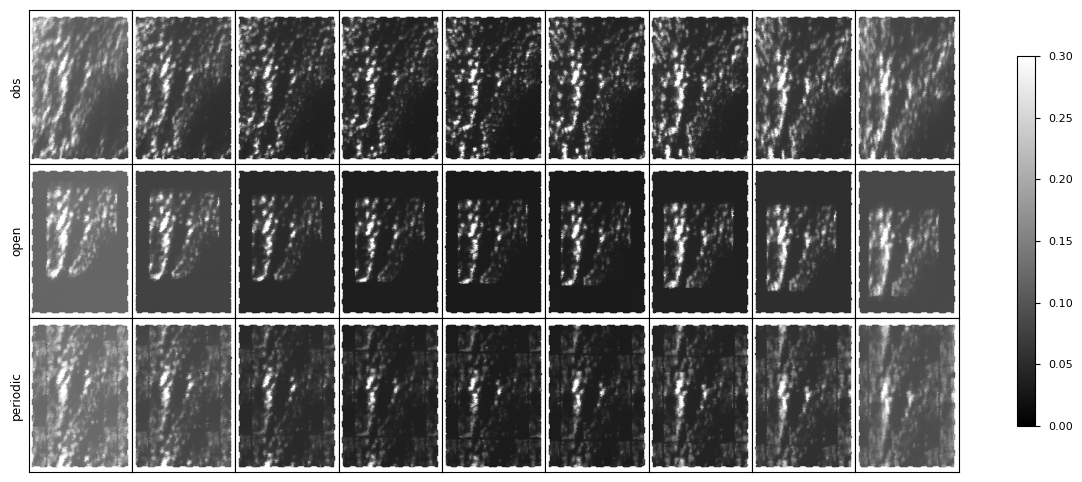

In [4]:
s = 2
vmin = 0
vmax = 0.3

plt.style.use('seaborn-v0_8-paper')
n = len(list(data.keys()))
f, ax = plt.subplots(n, 9, figsize=(15,2*n))
plt.subplots_adjust(wspace=0, hspace=0)
for i, k in enumerate(data):
    for j, cam in enumerate(data[k]['sl']):
        scat = ax[i, j].scatter(cam.ray_x.data, cam.ray_y.data, s=s, c=cam.I.data*np.pi/cam.mu0, marker='s', cmap='gray', vmin=vmin, vmax=vmax)
        ax[i, j].set_xlim([-4, 22])
        ax[i, j].set_ylim([-7, 25])
        ax[i, j].set_xticks([])
        ax[i, j].set_yticks([])
    ax[i, 0].set_ylabel(k)
plt.colorbar(scat, ax=ax[:], shrink=0.8)

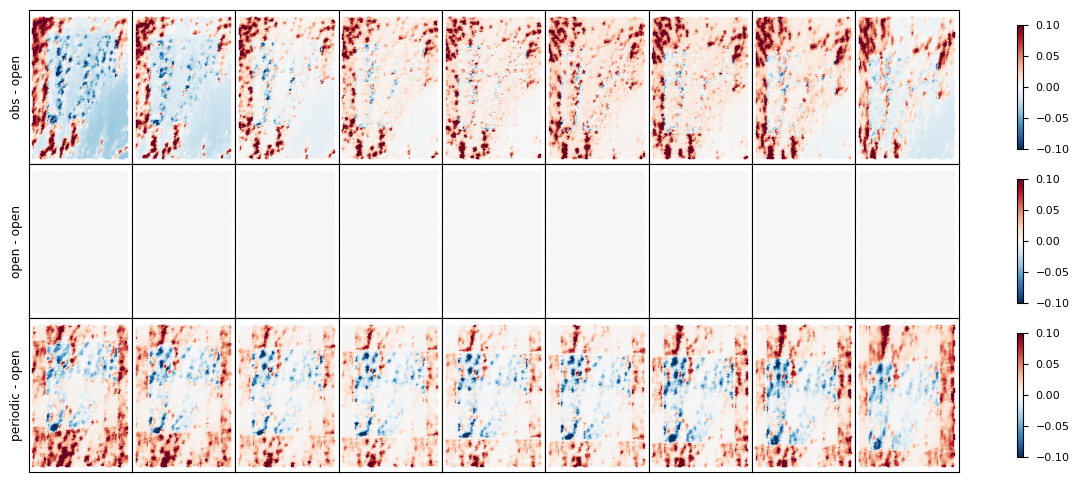

In [5]:
s = 2
vrange = [0.1, 0.1, 0.1]

plt.style.use('seaborn-v0_8-paper')
n = len(list(data.keys()))
f, ax = plt.subplots(n, 9, figsize=(15,2*n))
plt.subplots_adjust(wspace=0, hspace=0)
for i, k in enumerate(data):
    for j, (cam, defcam) in enumerate(zip(data[k]['sl'], data['open']['sl'])):
        I = (cam.I.data*np.pi/cam.mu0) - (defcam.I.data*np.pi/defcam.mu0)
        scat = ax[i, j].scatter(cam.ray_x.data, cam.ray_y.data, s=s, c=I, marker='s', cmap='RdBu_r', vmin=-vrange[i], vmax=vrange[i])
        ax[i, j].set_xlim([-4, 22])
        ax[i, j].set_ylim([-7, 25])
        ax[i, j].set_xticks([])
        ax[i, j].set_yticks([])
    ax[i, 0].set_ylabel('{} - open'.format(k))
    plt.colorbar(scat, ax=ax[i, :], shrink=0.8)

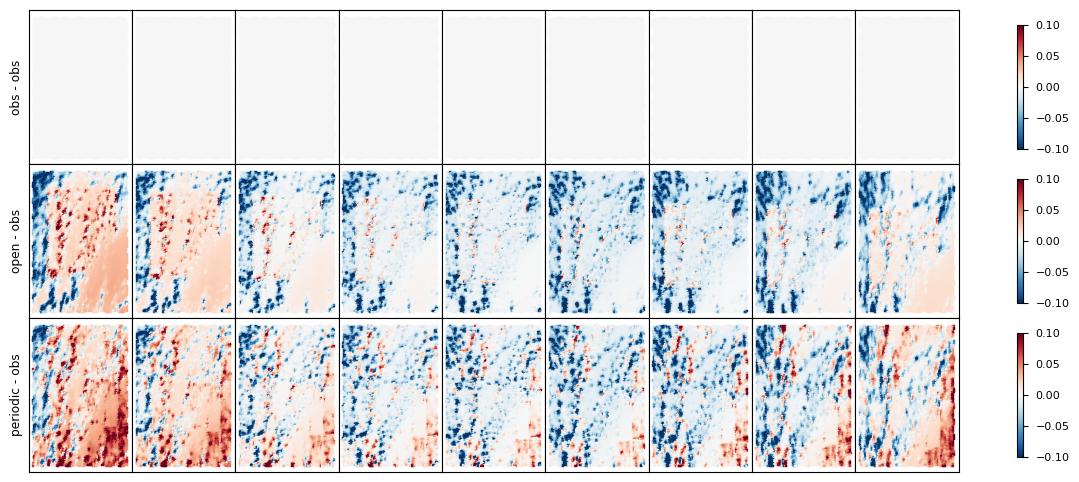

In [6]:
s = 2
vrange = [0.1, 0.1, 0.1]

plt.style.use('seaborn-v0_8-paper')
n = len(list(data.keys()))
f, ax = plt.subplots(n, 9, figsize=(15,2*n))
plt.subplots_adjust(wspace=0, hspace=0)
for i, k in enumerate(data):
    for j, (cam, defcam) in enumerate(zip(data[k]['sl'], data['obs']['sl'])):
        I = (cam.I.data*np.pi/cam.mu0) - (defcam.I.data*np.pi/defcam.mu0)
        scat = ax[i, j].scatter(cam.ray_x.data, cam.ray_y.data, s=s, c=I, marker='s', cmap='RdBu_r', vmin=-vrange[i], vmax=vrange[i])
        ax[i, j].set_xlim([-4, 22])
        ax[i, j].set_ylim([-7, 25])
        ax[i, j].set_xticks([])
        ax[i, j].set_yticks([])
    ax[i, 0].set_ylabel('{} - obs'.format(k))
    plt.colorbar(scat, ax=ax[i, :], shrink=0.8)

Text(0, 0.5, 'Periodic Extinction (1/km)')

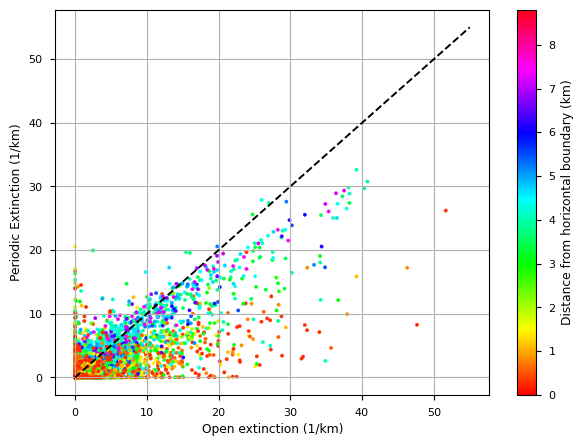

In [7]:
tmp = data['open']['cloud']
X, Y, Z = np.meshgrid(tmp.x.data, tmp.y.data, tmp.z.data, indexing='ij')
left_bottom = np.minimum(X, Y)
right_top = np.minimum(np.abs(17.6 - X), np.abs(17.6 - Y))
hdist = np.minimum(left_bottom, right_top)

f, ax = plt.subplots(1, 1, figsize=(7, 5))
scat = ax.scatter(np.ravel(data['open']['cloud'].extinction.data), np.ravel(data['periodic']['cloud'].extinction.data), s=6, c=np.ravel(hdist), cmap='hsv')
plt.colorbar(scat, ax=ax, label='Distance from horizontal boundary (km)')
ax.plot([0, 55], [0, 55], 'k--')
ax.grid()
ax.set_xlabel('Open extinction (1/km)')
ax.set_ylabel('Periodic Extinction (1/km)')

In [8]:
def rmse(x_r, x_t):
    return 100 * (np.sum((x_r - x_t)**2))**0.5 / (np.sum(x_t)**2)**0.5

def bias(x_r, x_t):
    return 100 * (np.sum(np.abs(x_r)) - np.sum(np.abs(x_t))) / (np.sum(np.abs(x_t)))

/tmp/ipykernel_197571/1660792670.py:2: RuntimeWarning: invalid value encountered in scalar divide
  return 100 * (np.sum((x_r - x_t)**2))**0.5 / (np.sum(x_t)**2)**0.5
/tmp/ipykernel_197571/1660792670.py:5: RuntimeWarning: invalid value encountered in scalar divide
  return 100 * (np.sum(np.abs(x_r)) - np.sum(np.abs(x_t))) / (np.sum(np.abs(x_t)))


Text(0.5, 0, 'Distance to Horizontal Edge')

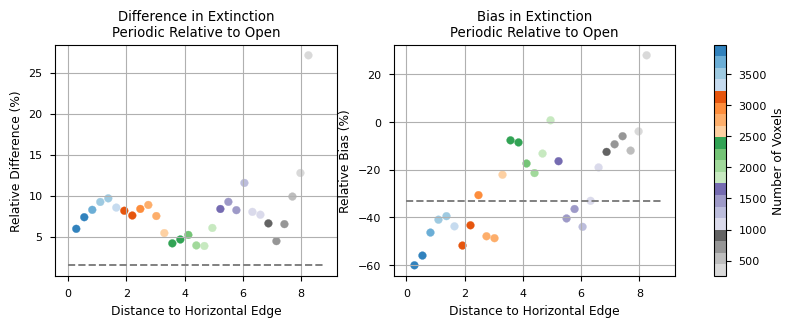

In [14]:
distances = np.arange(0, 9.1, 0.275) - 0.275/2
d = np.zeros(len(distances) - 1)
n = np.zeros(len(distances) - 1)
rel_diffs = np.zeros(len(distances) - 1)
rel_biases = np.zeros(len(distances) - 1)
for i in range(len(distances) - 1):
    d[i] = 0.5 * (distances[i] + distances[i+1])
    cond = (hdist > distances[i]) & (hdist < (distances[i+1]))
    n[i] = np.sum(cond)
    rel_diffs[i] = rmse(np.ravel(data['periodic']['cloud'].extinction.data[cond]), np.ravel(data['open']['cloud'].extinction.data[cond]))
    rel_biases[i] = bias(np.ravel(data['periodic']['cloud'].extinction.data[cond]), np.ravel(data['open']['cloud'].extinction.data[cond]))

overall_d = rmse(np.ravel(data['periodic']['cloud'].extinction.data), np.ravel(data['open']['cloud'].extinction.data))
overall_b = bias(np.ravel(data['periodic']['cloud'].extinction.data), np.ravel(data['open']['cloud'].extinction.data))

scat_cmap = 'tab20c_r'
f, ax = plt.subplots(1, 2, figsize=(10, 3), sharex=False)
ax[0].scatter(d, rel_diffs, c=n, cmap=scat_cmap)
ax[0].plot([0, 8.8], [overall_d, overall_d], '--', color='gray', label='Whole Domain')
scat = ax[1].scatter(d, rel_biases, c=n, cmap=scat_cmap)
plt.colorbar(scat, ax=ax[:], label='Number of Voxels')
ax[1].plot([0, 8.8], [overall_b, overall_b], '--', color='gray', label='Whole Domain')
ax[0].set_title('Difference in Extinction\nPeriodic Relative to Open')
ax[0].set_ylabel('Relative Difference (%)')
ax[1].set_title('Bias in Extinction\nPeriodic Relative to Open')
ax[1].set_ylabel('Relative Bias (%)')
ax[0].grid()
ax[1].grid()
ax[0].set_xlabel('Distance to Horizontal Edge')
ax[1].set_xlabel('Distance to Horizontal Edge')

In [10]:
import pandas as pd
import seaborn as sns

cond = cvm.cloud_volume_mask.data == 1

res = 1.1
distances = np.arange(0, 8.9+res, res) - res/2
d_strs = np.zeros(np.ravel(hdist[cond]).shape)
for i in range(len(distances) - 1):
    d_str = '{:.3f}'.format(0.5 * (distances[i] + distances[i+1]))
    cond_tmp = (hdist[cond] > distances[i]) & (hdist[cond] < (distances[i+1]))
    d_strs[cond_tmp] = d_str

df = pd.DataFrame(
    data=np.array([
        np.ravel(data['periodic']['cloud'].extinction.data[cond]),
        np.ravel(data['open']['cloud'].extinction.data[cond]),
        np.ravel(data['periodic']['cloud'].extinction.data[cond]) - np.ravel(data['open']['cloud'].extinction.data[cond]),
        (np.ravel(data['periodic']['cloud'].extinction.data[cond]) - np.ravel(data['open']['cloud'].extinction.data[cond])) / np.ravel(data['open']['cloud'].extinction.data[cond]),
        np.ravel(hdist[cond]),
        d_strs
    ]).T,
    columns=['periodic', 'open', 'difference', 'relative difference', 'horizontal distance float', 'horizontal distance']
)


/tmp/ipykernel_197571/3415182772.py:19: RuntimeWarning: divide by zero encountered in divide
  (np.ravel(data['periodic']['cloud'].extinction.data[cond]) - np.ravel(data['open']['cloud'].extinction.data[cond])) / np.ravel(data['open']['cloud'].extinction.data[cond]),
/tmp/ipykernel_197571/3415182772.py:19: RuntimeWarning: invalid value encountered in divide
  (np.ravel(data['periodic']['cloud'].extinction.data[cond]) - np.ravel(data['open']['cloud'].extinction.data[cond])) / np.ravel(data['open']['cloud'].extinction.data[cond]),


<Axes: xlabel='difference', ylabel='Count'>

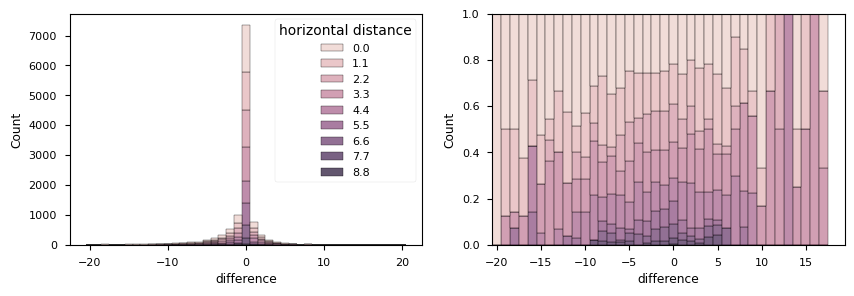

In [11]:
bins = np.arange(-20.5, 21.0, 1.0)
f, ax = plt.subplots(1, 2, figsize=(10,3))
sns.histplot(data=df, x='difference', ax=ax[0], bins=bins, hue='horizontal distance', multiple='stack')
sns.histplot(data=df, x='difference', ax=ax[1], bins=bins, hue='horizontal distance', multiple='fill', legend=None)


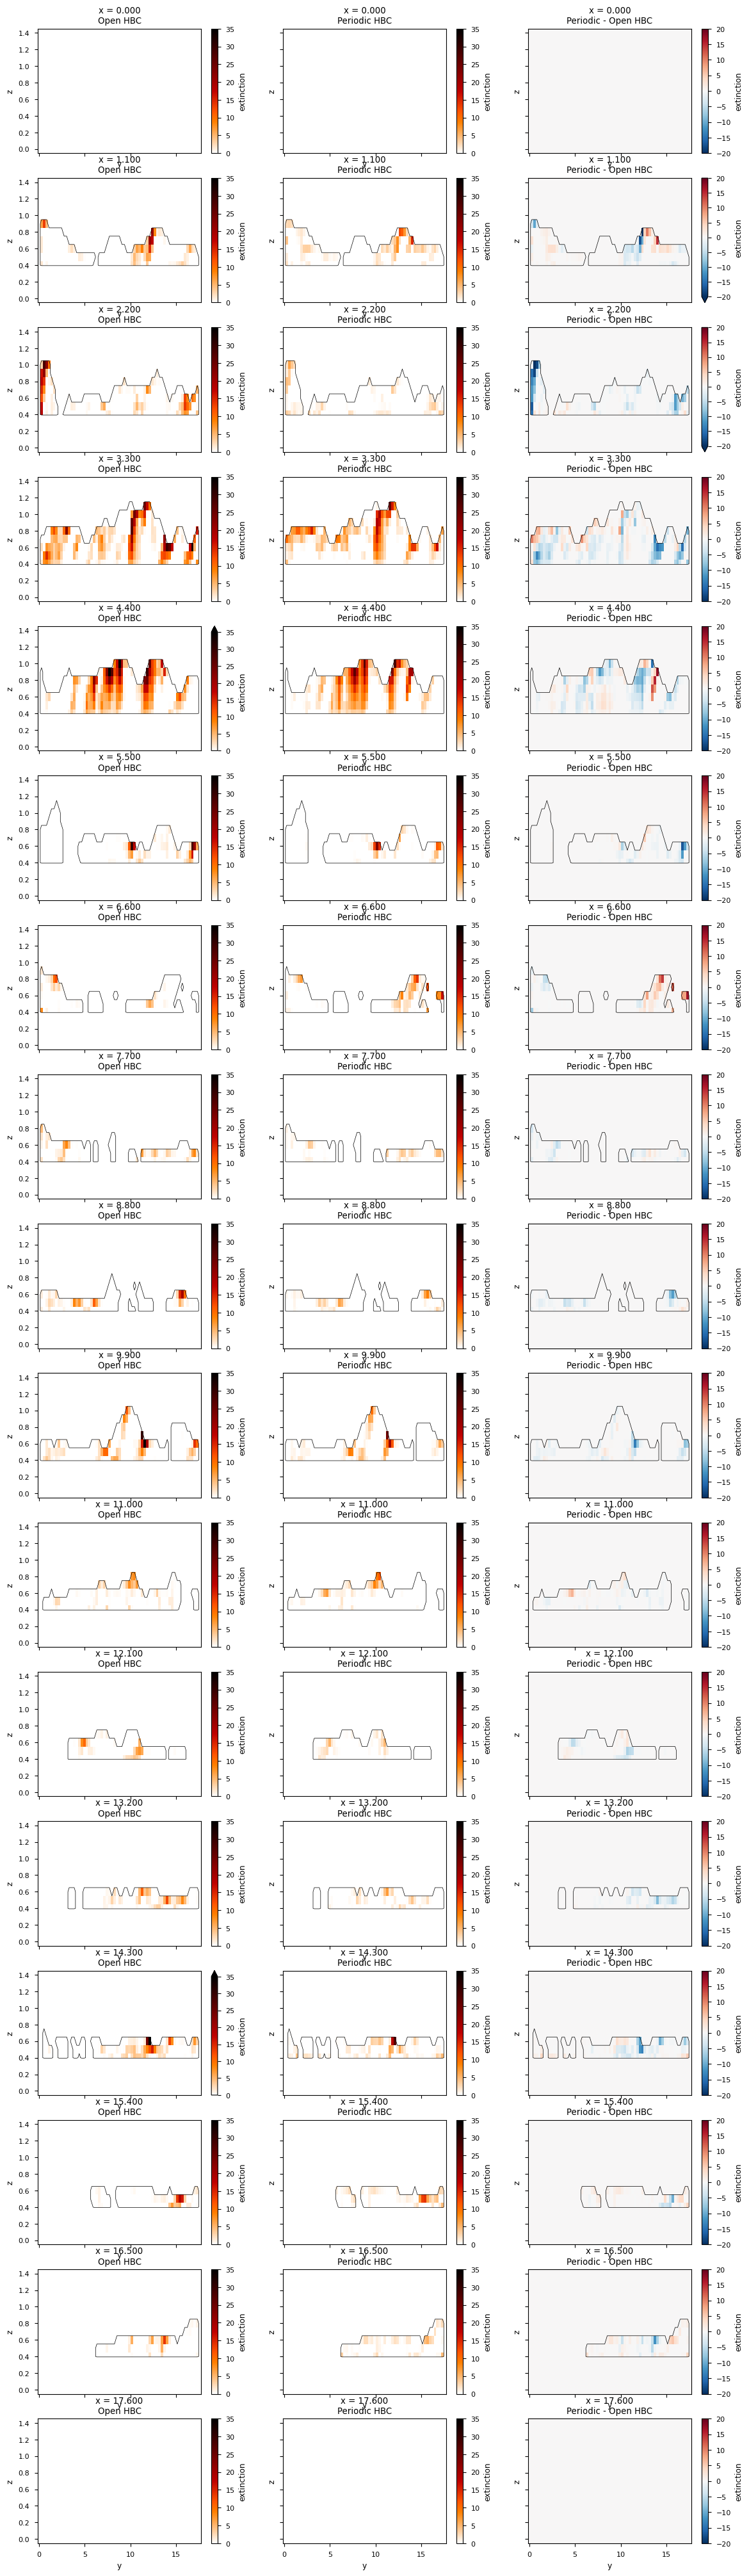

In [12]:
ext_cmap = 'gist_heat_r'
x = np.arange(0, 17.7, 1.1)
vmax = 35
vrange = 20
plt.style.use('default')
plt.style.use('seaborn-v0_8-paper')
f, ax = plt.subplots(len(x), 3, figsize=(14, 3*len(x)), sharey=True, sharex=True)
for i in range(len(x)):
    data['open']['cloud'].sel(x=x[i], method='nearest').extinction.plot(y='z', ax=ax[i, 0], vmin=0, vmax=vmax, cmap=ext_cmap)
    data['periodic']['cloud'].sel(x=x[i], method='nearest').extinction.plot(y='z', ax=ax[i, 1], vmin=0, vmax=vmax, cmap=ext_cmap)
    (data['periodic']['cloud'].extinction - data['open']['cloud'].extinction).sel(x=x[i], method='nearest').plot(y='z', ax=ax[i, 2], vmin=-vrange, vmax=vrange, cmap='RdBu_r')
    cvm.sel(x=x[i], method='nearest').cloud_volume_mask.plot.contour(y='z', levels=1, ax=ax[i, 0], colors='black', linewidths=0.5)
    cvm.sel(x=x[i], method='nearest').cloud_volume_mask.plot.contour(y='z', levels=1, ax=ax[i, 1], colors='black', linewidths=0.5)
    cvm.sel(x=x[i], method='nearest').cloud_volume_mask.plot.contour(y='z', levels=1, ax=ax[i, 2], colors='black', linewidths=0.5)
    ax[i, 0].set_title('x = {:.3f}\nOpen HBC'.format(x[i]))
    ax[i, 1].set_title('x = {:.3f}\nPeriodic HBC'.format(x[i]))
    ax[i, 2].set_title('x = {:.3f}\nPeriodic - Open HBC'.format(x[i]))

Text(0.5, 1.0, 'Periodic - Open')

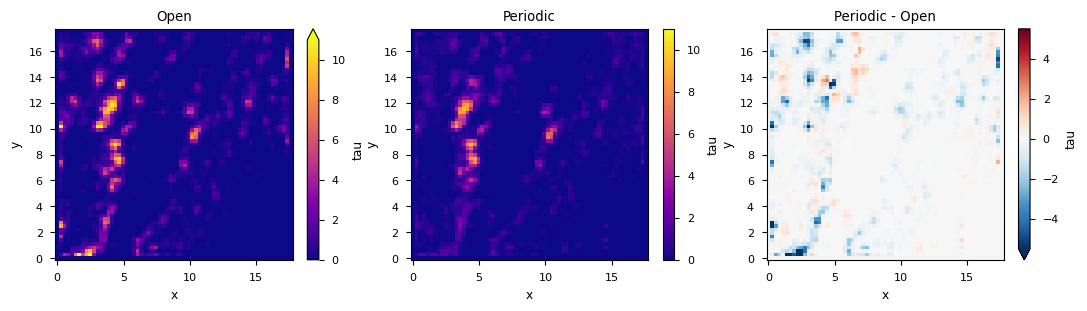

In [13]:
tau_cmap = 'plasma'
vmin = 0
vmax = 11
vrange = 5.5

cloud_open = data['open']['cloud']
cloud_periodic = data['periodic']['cloud']
cloud_open['tau'] = cloud_open.extinction.integrate('z')
cloud_periodic['tau'] = cloud_periodic.extinction.integrate('z')

f, ax = plt.subplots(1, 3, figsize=(13, 3))
cloud_open.tau.plot(y='y', ax=ax[0], vmin=vmin, vmax=vmax, cmap=tau_cmap)
cloud_periodic.tau.plot(y='y', ax=ax[1], vmin=vmin, vmax=vmax, cmap=tau_cmap)
(cloud_periodic.tau - cloud_open.tau).plot(y='y', ax=ax[2], vmin=-vrange, vmax=vrange, cmap='RdBu_r')
ax[0].set_title('Open')
ax[1].set_title('Periodic')
ax[2].set_title('Periodic - Open')